<a href="https://colab.research.google.com/github/snorzah/scudem/blob/main/SCUDEM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [129]:
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.integrate import solve_ivp


In [130]:
## 8kg Spider Monkey (Ateles), Adult Spider Monkey

## ENVIRONMENTAL FACTORS

b = 12.0        # Daylight duration / active foraging window (hours)
v = 1.0         # Canopy travel speed (m/s) [~3.6 km/h]
k = 10          # Smoothing Factor

##  METABOLIC & ENERGETIC PARAMETERS (kJ, kJ/h)

# Basal Metabolic Rate (kJ/h) — BMR = 293 * M^0.75 / 24
# Source: White & Seymour (2003, 2005)
# - https://www.pnas.org/doi/10.1073/pnas.0436428100
# - https://pubmed.ncbi.nlm.nih.gov/15855392/

C_0 = 60.0 #kJ/h

# Locomotion Cost Coefficient (kJ / (h * (m/s)^2))
# Source: Taylor et al. (1982)
# - https://pubmed.ncbi.nlm.nih.gov/7086334/

C_v = 25.0

# Initial Energy Reserve (kJ) — ~1.5 days of daily metabolic budget

E_0 = 3000.0

# Peak Group Food Intake Rate (kJ/h)
# Source: Pontzer et al. (2014)
# - https://www.pnas.org/doi/10.1073/pnas.1316940111

I_max = 424.0


# 4. SOCIAL & TRUST PARAMETERS

alpha = 0.15     # Trust formation rate
e_0 = 0.2       # Tolerated error threshold
#T0 = 0.5        # Initial trust level [0, 1]
# Gamma_i = 0.45  # Baseline greed for monkey i
# Gamma_j = 0.55  # Baseline greed for monkey j
S = 0.5 # sharing-to-trust constant

# Initial state vecotr [T_i, T_j, E_i, E_j]
y0 = [0.55, 0.45, 3000.0, 3000.0]

$$\frac{dT_i}{dt}=\alpha \max(e_0-e_j(t),0) (1-T_i) - \Gamma_j(t) \max(e_j(t)-e_0, 0) T_i$$
$$\frac{dT_j}{dt}=\alpha \max(e_0-e_i(t),0) (1-T_i) - \Gamma_i(t) \max(e_i(t)-e_0, 0) T_j$$
where $$\Gamma_i(t) = -ST_j+1$$ and $$\Gamma_j(t) = -ST_i+1$$
Plugging this in, we get the system of differential equations for trust:
$$\frac{dT_i}{dt}=\alpha \max(e_0-e_j(t),0) (1-T_i) - (1-ST_i) \max(e_j(t)-e_0, 0) T_i$$
$$\frac{dT_j}{dt}=\alpha \max(e_0-e_i(t),0) (1-T_i) - (1-ST_j) \max(e_i(t)-e_0, 0) T_j$$

In [131]:

# system of diffeq's


def I(t):
  return (I_max * np.log(1+np.exp(k*np.sin(np.pi * t/b)))) / np.log(1 + np.exp(k))

def system(t, Y):
  T_i, T_j, E_i, E_j = Y

  e_i = max(0.0, (E_0 - E_i) / E_0) #this should be a fraction of their total hunger reserve
  e_j = max(0.0, (E_0 - E_j) / E_0) #(hopefully) - hopeium

  dTidt = alpha * max([e_0 - e_j, 0]) * (1-T_i) - (-S*T_j+1) * max([e_j - e_0, 0]) * T_i
  dTjdt = alpha * max([e_0 - e_i, 0]) * (1-T_j) - (-S*T_i+1) * max([e_i - e_0, 0]) * T_j

  Gamma_i = -S*T_j + 1
  Gamma_j = -S*T_i + 1

  I_t = 1/2 * (1+Gamma_i-Gamma_j) * I(t) # Why the 1/2?
  I_j = 1/2 * (1+Gamma_j-Gamma_i) * I(t)


  v_t = v if (t % 24) < b else 0.0 #monkies are not moving while sleeping yo
  m = C_0 + C_v * (v_t**2)

  dEidt = I_t - m
  dEjdt = I_j - m

  return [dTidt, dTjdt, dEidt, dEjdt]


In [132]:
#solve ivp for72 day duration

timespan = (0,168)
timeeval = np.linspace(timespan[0], timespan[1], 7000)

sol = solve_ivp(system, timespan, y0, t_eval=timeeval)

T_i, T_j, E_i, E_j = sol.y
t = sol.t

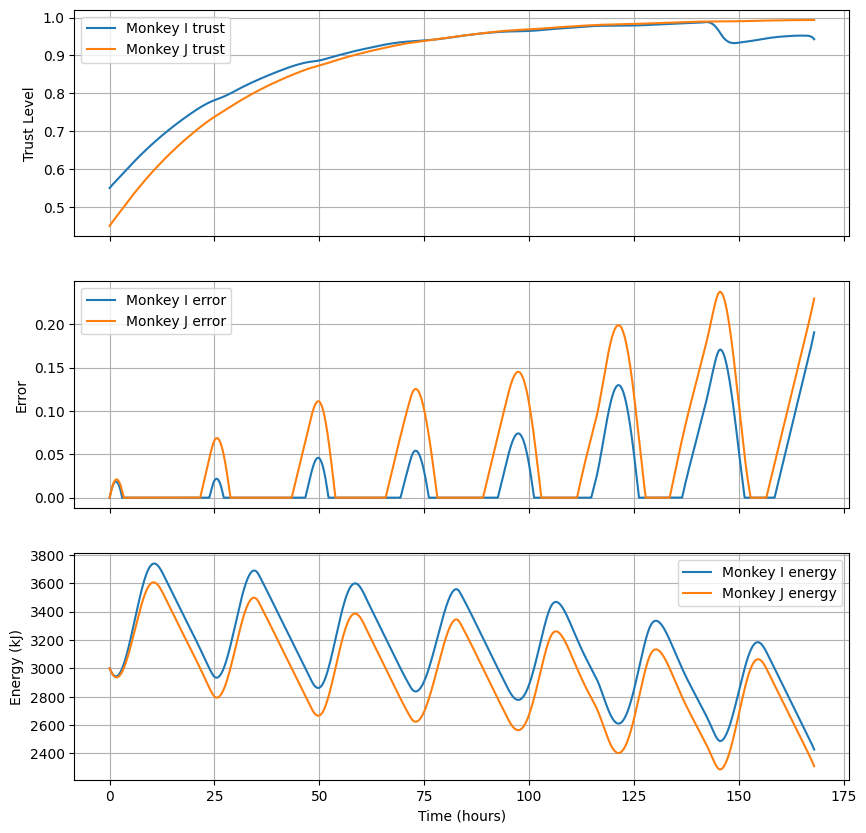

In [133]:
#graph time (hell ya i can see if it acc works frfr) - *it worked on the third try

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 10))

# Trust
ax1.plot(t, T_i, label='Monkey I trust')
ax1.plot(t, T_j, label='Monkey J trust')
ax1.set_ylabel('Trust Level')
ax1.legend()
ax1.grid(True)

# Error
e_i_arr = np.maximum(0.0, (E_0 - E_i) / E_0)
e_j_arr = np.maximum(0.0, (E_0 - E_j) / E_0)
ax2.plot(t, e_i_arr, label='Monkey I error')
ax2.plot(t, e_j_arr, label='Monkey J error')
ax2.set_ylabel('Error')
ax2.legend()
ax2.grid(True)

# Energy
ax3.plot(t, E_i, label='Monkey I energy')
ax3.plot(t, E_j, label='Monkey J energy')
ax3.set_xlabel('Time (hours)')
ax3.set_ylabel('Energy (kJ)')
ax3.legend()
ax3.grid(True)


plt.show()






# Code after this point is probably unused / outdated

In [134]:

#e_i = lambda t: np.sin(1/12 * t)**2
#e_j = lambda t: np.cos(1/12 * t)**2 # could make e_j and e_i related to E_i and E_j

t_0 = 0
t_f = 48
T_i0 = 0.3
T_j0 = 0.7
f = lambda t, T: np.array([dTidt(T[0], T[1], t), dTjdt(T[0], T[1], t)])
F = solve_ivp(f, [t_0, t_f], [T_i0, T_j0], t_eval=np.linspace(t_0, t_f, 1000))
T_i, T_j = F.y
t = F.t
plt.plot(t, T_i, label = "$T_i$")
plt.plot(t, T_j, label = "$T_j$")
plt.legend()

NameError: name 'dTidt' is not defined

In [ ]:
t = np.linspace(0, 48, 1000)

I_arr = I(t) # food intake rate

plt.plot(t, I_arr, label = 'Food Intake')

#Gamma_i = -S*T_j + 1
#Gamma_j = -S*T_i + 1
#I_i = lambda t: 1/2 * (1+Gamma_i-Gamma_j) * I(t)
#I_j = lambda t: 1/2 * (1+Gamma_j-Gamma_i) * I(t)

plt.plot(t, I_i(t), label = 'monkey i')
plt.plot(t, I_j(t), label = 'monkey j')
plt.legend()

In [ ]:
# greed as a function of time

plt.plot(t, Gamma_i, label = 'monkey i')
plt.plot(t, Gamma_j, label = 'monkey i')

In [ ]:
def dEidt(E, t):
  return I_i(t) - ((C_v*(v**2)) + (C_0))

def dEjdt(E, t):
  return I_j(t) - ((C_v*(v**2)) + (C_0))

t = np.linspace(0,50,100)

Ei = odeint(dEidt, E_0, t)
Ej = odeint(dEjdt, E_0, t)
plt.plot(t, Ei, label = 'monkey i')
plt.plot(t, Ej, label = 'monkey j')



plt.legend()